# CCD maps: residual amplitude per bin, before and after (James, meeting 2026-10-2x)

Independent check that the per-bin medians of the CCD (tree-ring) maps are right. Bricks are split into two halves
A and B. Maps are built from A only (16-px bins, as `ringmaps-dr10.fits`), then applied to B. For each map bin we
take the median offset of B's epochs **before** (raw map signal) and **after** the correction.

If the maps are correct, the per-bin medians after the correction are pure noise: the noise of B's median plus the
noise of A's map value (equal halves, so after ≈ √2 × noise of one half). The noise of a half is measured directly,
without any model, from the difference of two random quarters of B. Also shown: the April 2024 maps applied to B.

Sample: `ringmap_build` cache (v1 combined Gaia epochs of 000-063 with σ < 10 mas, two-line DCR removed), the same
stars the adopted maps were built from.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.append(os.path.abspath('..'))
from py_files import ringmap_build as rb, plot_style as ps
ps.apply()
OUT = 'plots/'
BIN = 16
MIN_N = 10   # epochs per bin in each part
PIX = rb.PIXSCALE
S, ccds = rb.load_samples()
h = (S['brickid'].astype(np.int64) * 2654435761 % 2**32)
A = (h % 2) == 0
B = ~A
B1 = B & ((h // 2) % 2 == 0)
B2 = B & ~B1
print(f"{len(S['x']):,} epochs; A {A.sum():,}, B {B.sum():,}")

293,966,402 epochs; A 147,508,244, B 146,458,158


In [2]:
def medians(S, sel, dx, dy):
    T = dict(S); T['dx'], T['dy'] = dx, dy
    return rb.binned_medians(T, sel, BIN)

mA = rb.binned_medians(S, A, BIN)
before = rb.binned_medians(S, B, BIN)
q1, q2 = rb.binned_medians(S, B1, BIN), rb.binned_medians(S, B2, BIN)
# corrections for every epoch from A's maps (only B's are used) and from the 2024 maps
cx, cy = np.zeros(len(S['x']), np.float32), np.zeros(len(S['x']), np.float32)
cx[B], cy[B] = rb.apply_maps(S, B, rb.as_dict(mA[0], mA[1], ccds), BIN)
after = medians(S, B, S['dx'] - cx, S['dy'] - cy)
ox, oy = np.zeros(len(S['x']), np.float32), np.zeros(len(S['x']), np.float32)
ox[B], oy[B] = rb.apply_maps(S, B, rb.old_maps(), 16)
after_old = medians(S, B, S['dx'] - ox, S['dy'] - oy)

In [3]:
def rms(v):
    return float(np.sqrt(np.mean(v**2)))

n_maps = mA[2].shape[0]
band_of_map = np.arange(n_maps) % 4
rows, hist = [], {}
for j, band in enumerate(rb.BANDS):
    sel = (band_of_map == j)[:, None, None] & (mA[2] >= MIN_N) & (q1[2] >= MIN_N // 2) & (q2[2] >= MIN_N // 2) & (before[2] >= MIN_N)
    for c, comp in enumerate(('x', 'y')):
        b0, b1, b2 = before[c][sel] * PIX, after[c][sel] * PIX, after_old[c][sel] * PIX
        # q1, q2 each have ~1/2 of B's epochs: var(q1 - q2) = 2 var(q) = 4 var(B median) -> sigma(B median) = rms / 2
        noise_B = rms((q1[c][sel] - q2[c][sel]) * PIX) / 2
        # B's noise + A's map noise; the map is interpolated bilinearly between bin centres, which averages
        # neighbouring bins: for epochs spread uniformly over a bin the map noise variance is (2/3)^2 = 4/9 of a bin's
        expect_after = noise_B * np.sqrt(1 + 4 / 9)
        tail = np.mean(np.abs(b1) > 5 * expect_after)
        rows.append((band, comp, int(sel.sum()), rms(b0), rms(b1), expect_after, rms(b2), float(np.median(b1)),
                     np.sqrt(max(rms(b1)**2 - expect_after**2, 0)), tail))
        hist[(band, comp)] = (b0, b1, b2, expect_after)
print('per-bin median offsets of held-out half B (mas), bins with >= %d epochs' % MIN_N)
print(f"{'band':4s} {'axis':4s} {'bins':>8s} {'before':>7s} {'after':>7s} {'noise':>7s} {'2024':>7s} {'median':>7s} {'excess':>7s} {'>5sig':>7s}")
for r in rows:
    print(f'{r[0]:4s} {r[1]:4s} {r[2]:8,d} {r[3]:7.2f} {r[4]:7.2f} {r[5]:7.2f} {r[6]:7.2f} {r[7]:+7.2f} {r[8]:7.2f} {r[9]:7.2%}')

per-bin median offsets of held-out half B (mas), bins with >= 10 epochs
band axis     bins  before   after   noise    2024  median  excess   >5sig
g    x    1,170,601   11.98    5.72    5.71   23.95   -0.04    0.30   0.19%
g    y    1,170,601    8.61    4.73    4.82   23.11   -0.01    0.00   0.07%
r    x    1,827,798   11.88    4.54    4.41   22.04   -0.03    1.09   0.31%
r    y    1,827,798    7.64    3.45    3.46   19.79   +0.04    0.00   0.09%
i    x    1,697,940   11.54    4.42    4.32   24.31   -0.01    0.90   0.32%
i    y    1,697,940    8.07    3.45    3.46   23.61   -0.01    0.00   0.10%
z    x    1,763,174    9.12    3.90    3.93   25.54   +0.00    0.00   0.21%
z    y    1,763,174    7.30    3.18    3.35   25.43   +0.04    0.00   0.08%


`before` = rms of per-bin medians with no map (signal + noise); `after` = with A's maps; `noise` = expected rms
of `after` if the maps were perfect: noise of B's medians (measured from two quarters) plus the noise of A's maps,
which bilinear interpolation reduces to 4/9 of a bin's variance; `excess` = √(after² − noise²) = map error beyond
noise; `>5sig` = fraction of bins more than 5× the noise from zero (tails); `2024` = with the April 2024 maps.

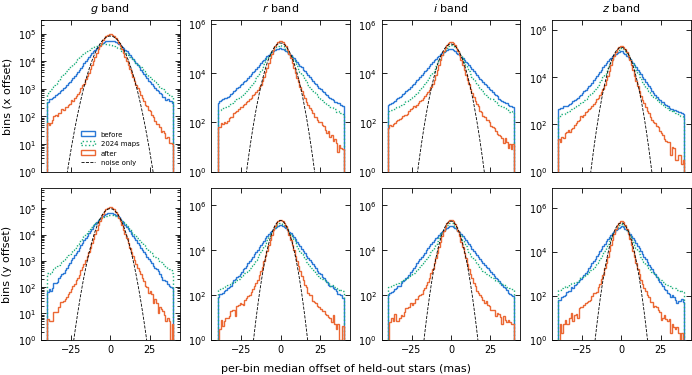

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(ps.PAGE, 3.8), sharex=True, constrained_layout=True)
edges = np.linspace(-40, 40, 81)
for c, comp in enumerate(('x', 'y')):
    for j, band in enumerate(rb.BANDS):
        ax = axes[c, j]
        b0, b1, b2, e = hist[(band, comp)]
        ax.hist(b0, edges, histtype='step', color=ps.SERIES[0], label='before')
        ax.hist(b2, edges, histtype='step', color=ps.SERIES[2], ls=':', label='2024 maps')
        ax.hist(b1, edges, histtype='step', color=ps.SERIES[1], label='after')
        g = len(b1) * (edges[1] - edges[0]) / (np.sqrt(2 * np.pi) * e) * np.exp(-0.5 * (0.5 * (edges[1:] + edges[:-1]) / e)**2)
        ax.plot(0.5 * (edges[1:] + edges[:-1]), g, color='k', lw=0.6, ls='--', label='noise only')
        ax.set_yscale('log'); ax.set_ylim(1, None)
        if c == 0:
            ax.set_title(f'${band}$ band')
    axes[c, 0].set_ylabel(f'bins ({comp} offset)')
axes[0, 0].legend(fontsize=5)
fig.supxlabel('per-bin median offset of held-out stars (mas)', fontsize=8)
plt.savefig(OUT + 'ringmap_bin_residuals.pdf')